In [23]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

alcohol=0
n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 15. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 500*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second

tau_z   = 10*second      
r0      = 3*Hz           # baseline E population rate
kz      = 8.0            # sigmoid steepness
u0      = 0.2            

Iz_max_E = 50*pA         
eta_I    = 0 #0.3  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3

# Alcohol effect strengths (fractions)
ALC_RED_AMPA_E = 0.1   # X% reduction of excitatory drive onto E
ALC_RED_AMPA_I = 0.5   # X% increase of excitatory drive onto I
ALC_INC_GABA_E = 0.2   # X% increase of inhibitory drive onto E
ALC_INC_GABA_I = 0.2   # X% decrease of inhibitory drive onto I



kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(43,47),range(33,37)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training,alcohol):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn + I_z) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * g_AMPA_E_hsp * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E    * g_GABA_E_hsp * (1 + ALC_INC_GABA_E * alc) * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1
    I_z = Iz_max_E * z_shared : amp
    z_shared : 1 (shared)
    Iz_max_E : amp (shared)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dg_AMPA_E_hsp/dt = ((1 - g_AMPA_E_hsp) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_ins_AMPA_E
                - (g_AMPA_E_hsp - 0.1) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_int_AMPA_E) : 1

    dg_GABA_E_hsp/dt = (-(g_GABA_E_hsp - 0.1) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_int_GABA_E
                + (1 - g_GABA_E_hsp) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn + I_z) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (1 - ALC_RED_AMPA_I * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (1 + ALC_RED_AMPA_I * alc) * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp * (1 + ALC_INC_GABA_I * alc) * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    I_z = eta_I * Iz_max_E * z_shared : amp
    z_shared : 1 (shared)
    Iz_max_E : amp (shared)
    eta_I : 1 (shared)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((-r_est +target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((-r_est + target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''
    z_container = NeuronGroup(1, '''
            r_in : Hz  # will be set from rate_container_E
            u = r_in/r0 - 1 : 1
            s = 1/(1 + exp(-kz*(u - u0))) : 1
            dz/dt = (s - z)/tau_z : 1
        ''', method='euler', name='z_container')

    z_container.z = 0.0
    z_container.r_in = r0

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.g_AMPA_E_hsp = 0.3  
    P_E.g_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 500*second   #50'000
    P_E.tau_int_AMPA_E = 500*second    #5'000
    P_E.tau_ins_GABA_E = 500*second   
    P_E.tau_int_GABA_E = 500*second   
    P_E.Iz_max_E = Iz_max_E
    #P_E.z_shared = linked_var(z_container, 'z')


    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.3  
    P_I.g_GABA_I_hsp = 0.3  
    P_I.tau_ins_AMPA_I = 500000000*second   
    P_I.tau_int_AMPA_I = 50000000*second    
    P_I.tau_ins_GABA_I = 500000000*second   
    P_I.tau_int_GABA_I = 50000000*second
    P_I.Iz_max_E = Iz_max_E
    P_I.eta_I    = eta_I

    #P_I.z_shared = linked_var(z_container, 'z')

    P_E.t_on  = 10000*second
    P_E.t_off = 100*second#700*second#1000*second
    P_I.t_on  = 10000*second
    P_I.t_off = 100*second#700*second#1000*second

    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(j='i')                 

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
            s_AMPA_ext += w  
            ''', method='euler', name='PG_E')
        C_PG_E.connect(j='i')  

        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
            s_AMPA += w  
            ''', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        ''', method='euler', name='E_I') #        x_postE_post += 1.0 
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.2
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        # w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        # w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        # w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        # w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        # w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    C_r_to_z = Synapses(rate_container_E, z_container,
                    model='r_in_post = r_pop_E_pre : Hz (summed)',
                    method='euler', name='C_r_to_z')
    C_r_to_z.connect(i=0, j=0)

    C_zE = Synapses(z_container, P_E,
                model='z_shared_post = z_pre : 1 (summed)',
                method='euler')
    C_zE.connect()

    C_zI = Synapses(z_container, P_I,
                    model='z_shared_post = z_pre : 1 (summed)',
                    method='euler')
    C_zI.connect()
    
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'g_AMPA_E_hsp', record=True, dt=record_dt, name='g_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'g_GABA_E_hsp', record=True, dt=record_dt, name='g_GABA_E_hsp')
    gAMPA_mon_I = StateMonitor(P_I, 'g_AMPA_I_hsp', record=True, dt=record_dt, name='g_AMPA_I_hsp')
    gGABA_mon_I = StateMonitor(P_I, 'g_GABA_I_hsp', record=True, dt=record_dt, name='g_GABA_I_hsp')

    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')

# def train(N_train,alcohol,target_rate = 10*Hz):
#     net = build_network(True,alcohol=alcohol,target_rate=target_rate)
#     for i in range(N_train): 
#         show_img(net, index = i)
#         print(i)

#     save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
#     save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
#     save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
#     save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
#     save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
#     return net


def test(N_test,alcohol,show_time = 1000*ms):
    net = build_network(False,alcohol=alcohol)
    for i in range(N_test):
        show_rand_rate(net,show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


In [7]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

alcohol=0
n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 15. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 500*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second

tau_z   = 10*second      
r0      = 3*Hz           # baseline E population rate
kz      = 8.0            # sigmoid steepness
u0      = 0.2            

Iz_max_E = 50*pA         
eta_I    = 0 #0.3  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3

# Alcohol effect strengths (fractions)
ALC_RED_AMPA_E = 0.1   # X% reduction of excitatory drive onto E
ALC_RED_AMPA_I = 0.5   # X% increase of excitatory drive onto I
ALC_INC_GABA_E = 0.2   # X% increase of inhibitory drive onto E
ALC_INC_GABA_I = 0.2   # X% decrease of inhibitory drive onto I



kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,48),range(32,38)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training,alcohol):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn + I_z) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * g_AMPA_E_hsp * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E    * g_GABA_E_hsp * (1 + ALC_INC_GABA_E * alc) * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1
    I_z = Iz_max_E * z_shared : amp
    z_shared : 1 (linked)
    Iz_max_E : amp (shared)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dg_AMPA_E_hsp/dt = ((1 - g_AMPA_E_hsp) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_ins_AMPA_E
                - (g_AMPA_E_hsp - 0.1) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_int_AMPA_E) : 1

    dg_GABA_E_hsp/dt = (-(g_GABA_E_hsp - 0.1) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_int_GABA_E
                + (1 - g_GABA_E_hsp) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn + I_z) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (1 - ALC_RED_AMPA_I * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (1 + ALC_RED_AMPA_I * alc) * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp * (1 + ALC_INC_GABA_I * alc) * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    I_z = eta_I * Iz_max_E * z_shared : amp
    z_shared : 1 (linked)
    Iz_max_E : amp (shared)
    eta_I : 1 (shared)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((-r_est +target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((-r_est + target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''
    z_container = NeuronGroup(1, '''
            r_in : Hz  # will be set from rate_container_E
            u = r_in/r0 - 1 : 1
            s = 1/(1 + exp(-kz*(u - u0))) : 1
            dz/dt = (s - z)/tau_z : 1
        ''', method='euler', name='z_container')

    z_container.z = 0.0
    z_container.r_in = r0

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.g_AMPA_E_hsp = 0.3  
    P_E.g_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 500*second   #50'000
    P_E.tau_int_AMPA_E = 500*second    #5'000
    P_E.tau_ins_GABA_E = 500*second   
    P_E.tau_int_GABA_E = 500*second   
    P_E.Iz_max_E = Iz_max_E
    P_E.z_shared = linked_var(z_container, 'z')


    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.3  
    P_I.g_GABA_I_hsp = 0.3  
    P_I.tau_ins_AMPA_I = 500000000*second   
    P_I.tau_int_AMPA_I = 50000000*second    
    P_I.tau_ins_GABA_I = 500000000*second   
    P_I.tau_int_GABA_I = 50000000*second
    P_I.Iz_max_E = Iz_max_E
    P_I.eta_I    = eta_I
    P_I.z_shared = linked_var(z_container, 'z')

    P_E.t_on  = 10000*second
    P_E.t_off = 100*second#700*second#1000*second
    P_I.t_on  = 10000*second
    P_I.t_off = 100*second#700*second#1000*second

    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(j='i')                 

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
            s_AMPA_ext += w  
            ''', method='euler', name='PG_E')
        C_PG_E.connect(j='i')  

        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
            s_AMPA += w  
            ''', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        ''', method='euler', name='E_I') #        x_postE_post += 1.0 
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.2
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        # w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        # w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        # w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        # w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        # w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    C_r_to_z = Synapses(rate_container_E, z_container,
                    model='r_in_post = r_pop_E_pre : Hz (summed)',
                    method='euler', name='C_r_to_z')
    C_r_to_z.connect(i=0, j=0)

    # C_zE = Synapses(z_container, P_E,
    #             model='z_shared_post = z_pre : 1 (summed)',
    #             method='euler')
    # C_zE.connect()

    # C_zI = Synapses(z_container, P_I,
    #                 model='z_shared_post = z_pre : 1 (summed)',
    #                 method='euler')
    # C_zI.connect()
    
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'g_AMPA_E_hsp', record=True, dt=record_dt, name='g_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'g_GABA_E_hsp', record=True, dt=record_dt, name='g_GABA_E_hsp')
    gAMPA_mon_I = StateMonitor(P_I, 'g_AMPA_I_hsp', record=True, dt=record_dt, name='g_AMPA_I_hsp')
    gGABA_mon_I = StateMonitor(P_I, 'g_GABA_I_hsp', record=True, dt=record_dt, name='g_GABA_I_hsp')

    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')

# def train(N_train,alcohol,target_rate = 10*Hz):
#     net = build_network(True,alcohol=alcohol,target_rate=target_rate)
#     for i in range(N_train): 
#         show_img(net, index = i)
#         print(i)

#     save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
#     save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
#     save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
#     save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
#     save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
#     return net


def test(N_test,alcohol,show_time = 1000*ms):
    net = build_network(False,alcohol=alcohol)
    for i in range(N_test):
        show_rand_rate(net,show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


In [ ]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

alcohol=0
n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 15. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 500*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second

tau_z   = 10*second      
r0      = 3*Hz           # baseline E population rate
kz      = 8.0            # sigmoid steepness
u0      = 0.2            

Iz_max_E = 50*pA         
eta_I    = 0 #0.3  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3

# Alcohol effect strengths (fractions)
ALC_RED_AMPA_E = 0.1   # X% reduction of excitatory drive onto E
ALC_RED_AMPA_I = 0.5   # X% increase of excitatory drive onto I
ALC_INC_GABA_E = 0.2   # X% increase of inhibitory drive onto E
ALC_INC_GABA_I = 0.2   # X% decrease of inhibitory drive onto I



kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,48),range(32,38)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training,alcohol):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn + I_z) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * g_AMPA_E_hsp * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E    * g_GABA_E_hsp * (1 + ALC_INC_GABA_E * alc) * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1
    I_z = Iz_max_E * z_shared : amp
    z_shared : 1 (linked)
    Iz_max_E : amp (shared)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dg_AMPA_E_hsp/dt = ((1 - g_AMPA_E_hsp) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_ins_AMPA_E
                - (g_AMPA_E_hsp - 0.1) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_int_AMPA_E) : 1

    dg_GABA_E_hsp/dt = (-(g_GABA_E_hsp - 0.1) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_int_GABA_E
                + (1 - g_GABA_E_hsp) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn + I_z) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (1 - ALC_RED_AMPA_I * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (1 + ALC_RED_AMPA_I * alc) * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp * (1 + ALC_INC_GABA_I * alc) * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    I_z = eta_I * Iz_max_E * z_shared : amp
    z_shared : 1 (linked)
    Iz_max_E : amp (shared)
    eta_I : 1 (shared)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((-r_est +target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((-r_est + target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''
    z_container = NeuronGroup(1, '''
            r_in : Hz  # will be set from rate_container_E
            u = r_in/r0 - 1 : 1
            s = 1/(1 + exp(-kz*(u - u0))) : 1
            dz/dt = (s - z)/tau_z : 1
        ''', method='euler', name='z_container')

    z_container.z = 0.0
    z_container.r_in = r0

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.g_AMPA_E_hsp = 0.3  
    P_E.g_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 500*second   #50'000
    P_E.tau_int_AMPA_E = 500*second    #5'000
    P_E.tau_ins_GABA_E = 500*second   
    P_E.tau_int_GABA_E = 500*second   
    P_E.Iz_max_E = Iz_max_E
    P_E.z_shared = linked_var(z_container, 'z')


    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.3  
    P_I.g_GABA_I_hsp = 0.3  
    P_I.tau_ins_AMPA_I = 500000000*second   
    P_I.tau_int_AMPA_I = 50000000*second    
    P_I.tau_ins_GABA_I = 500000000*second   
    P_I.tau_int_GABA_I = 50000000*second
    P_I.Iz_max_E = Iz_max_E
    P_I.eta_I    = eta_I
    P_I.z_shared = linked_var(z_container, 'z')

    P_E.t_on  = 10000*second
    P_E.t_off = 100*second#700*second#1000*second
    P_I.t_on  = 10000*second
    P_I.t_off = 100*second#700*second#1000*second

    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(j='i')                 

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
            s_AMPA_ext += w  
            ''', method='euler', name='PG_E')
        C_PG_E.connect(j='i')  

        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
            s_AMPA += w  
            ''', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        ''', method='euler', name='E_I') #        x_postE_post += 1.0 
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.2
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        # w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        # w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        # w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        # w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        # w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    C_r_to_z = Synapses(rate_container_E, z_container,
                    model='r_in_post = r_pop_E_pre : Hz (summed)',
                    method='euler', name='C_r_to_z')
    C_r_to_z.connect(i=0, j=0)

    # C_zE = Synapses(z_container, P_E,
    #             model='z_shared_post = z_pre : 1 (summed)',
    #             method='euler')
    # C_zE.connect()

    # C_zI = Synapses(z_container, P_I,
    #                 model='z_shared_post = z_pre : 1 (summed)',
    #                 method='euler')
    # C_zI.connect()
    
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'g_AMPA_E_hsp', record=True, dt=record_dt, name='g_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'g_GABA_E_hsp', record=True, dt=record_dt, name='g_GABA_E_hsp')
    gAMPA_mon_I = StateMonitor(P_I, 'g_AMPA_I_hsp', record=True, dt=record_dt, name='g_AMPA_I_hsp')
    gGABA_mon_I = StateMonitor(P_I, 'g_GABA_I_hsp', record=True, dt=record_dt, name='g_GABA_I_hsp')

    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')

# def train(N_train,alcohol,target_rate = 10*Hz):
#     net = build_network(True,alcohol=alcohol,target_rate=target_rate)
#     for i in range(N_train): 
#         show_img(net, index = i)
#         print(i)

#     save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
#     save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
#     save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
#     save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
#     save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
#     return net


def test(N_test,alcohol,show_time = 1000*ms):
    net = build_network(False,alcohol=alcohol)
    for i in range(N_test):
        show_rand_rate(net,show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


INFO:root:building '_cython_magic_d32f57a352b92e9002ad0b68794590f9' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_d32f57a352b92e9002ad0b68794590f9.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_d32f57a352b92e9002ad0b68794590f9.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_d32f57a352b92e9002ad0b68794590f9.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([38.11505432, 37.74797012, 40.45088654, ..., 37.45104626,
       35.58664234, 43.22749272]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 10. ks
126.597 s (1%) simulated in 10s, estimated 13m 0s remaining.
264.223 s (2%) simulated in 20s, estimated 12m 17s remaining.
0.390085 ks (3%) simulated in 30s, estimated 12m 19s remaining.
0.509218 ks (5%) simulated in 40s, estimated 12m 26s remaining.
0.637731 ks (6%) simulated in 50s, estimated 12m 14s remaining.
0.756113 ks (7%) simulated in 1m 0s, estimated 12m 14s remaining.
0.871325 ks (8%) simulated in 1m 10s, estimated 12m 13s remaining.
0.996752 ks (9%) simulated in 1m 20s, estimated 12m 3s remaining.
1.110237 ks (11%) simulated in 1m 30s, estimated 12m 1s remaining.
1.217371 ks (12%) simulated in 1m 40s, estimated 12m 1s remaining.
1.337286 ks (13%) simulated in 1m 50s, estimated 11m 53s remaining.
1.446614 ks (14%) simulated in 2m 0s, estimated 11m 50s remaining.
1.560266 ks (15%) simulated in 2m 10s, estimated 11m 43s remaining.
1.671303 ks (16%) simulated in 2m 20s, estimated 11m 38s remaining.
1.79139 ks (17%) simulated

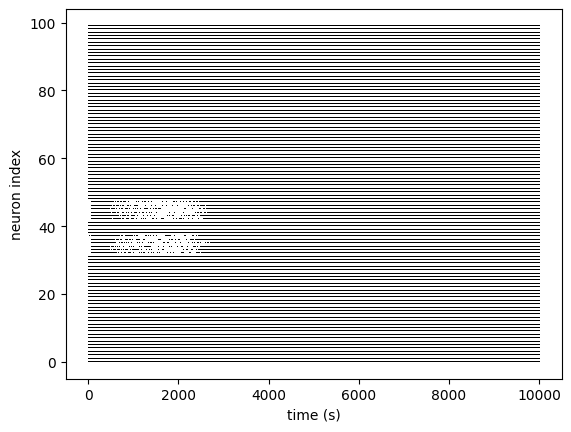

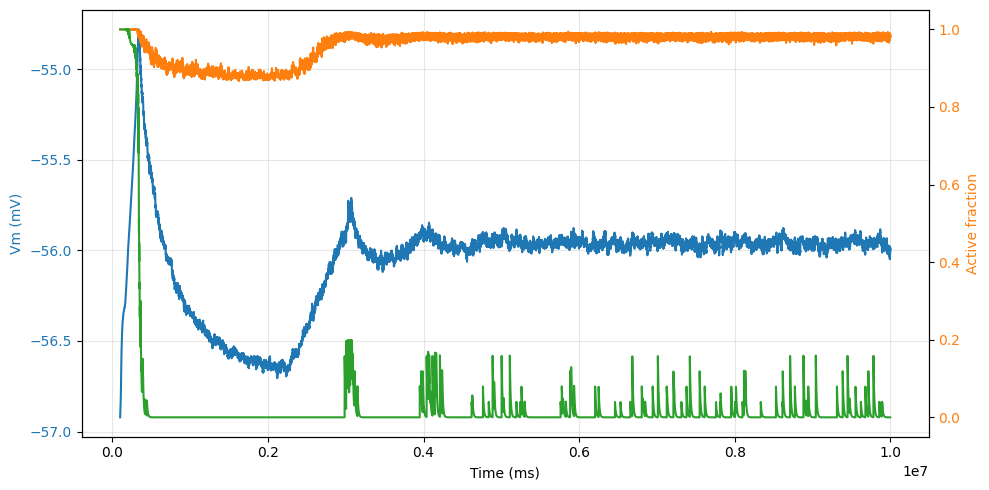

In [8]:
start_scope()
defaultclock.dt = 1000 * us
net = test(1,alcohol=False,show_time=10000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.1 
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

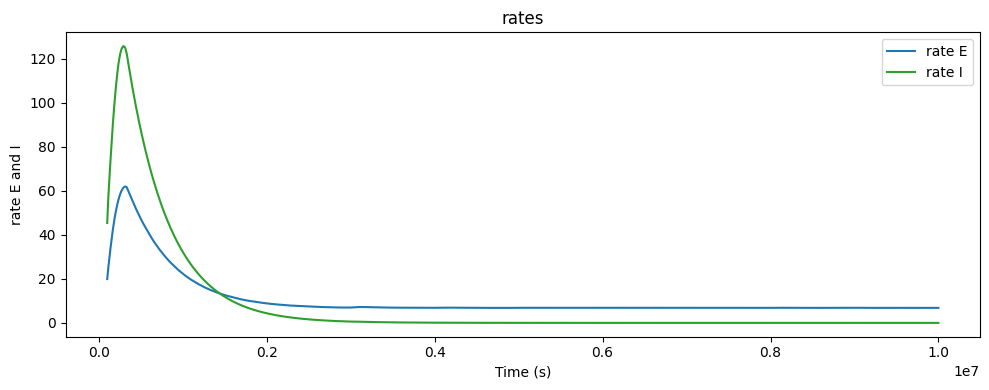

In [9]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E and I')
plt.title('rates')
plt.legend()
plt.tight_layout()

In [42]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 15. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 500*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second

tau_z   = 10*second      
r0      = 3*Hz           # baseline E population rate
kz      = 8.0            # sigmoid steepness
u0      = 0.2            

Iz_max_E = 50*pA         
eta_I    = 0 #0.3  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,48),range(32,38)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * g_AMPA_E_hsp * (1 + 0.3*z_shared) * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E    * g_GABA_E_hsp  * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     :1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1
    z_shared : 1 (linked)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dg_AMPA_E_hsp/dt = ((1 - g_AMPA_E_hsp) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_ins_AMPA_E
                - (g_AMPA_E_hsp - 0.1) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_int_AMPA_E) : 1

    dg_GABA_E_hsp/dt = (-(g_GABA_E_hsp - 0.1) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_int_GABA_E
                + (1 - g_GABA_E_hsp) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (1 + 0.3*z_shared) * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp  * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    z_shared : 1 (linked)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((-r_est +target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((-r_est + target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''
    z_container = NeuronGroup(1, '''
            r_in : Hz  
            u = r_in/r0 - 1 : 1
            s = 1/(1 + exp(-kz*(u - u0))) : 1
            dz/dt = (s - z)/tau_z : 1
        ''', method='euler', name='z_container')

    z_container.z = 0.0
    z_container.r_in = r0

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.g_AMPA_E_hsp = 0.3  
    P_E.g_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 5000*second   #50'000
    P_E.tau_int_AMPA_E = 5000*second    #5'000
    P_E.tau_ins_GABA_E = 5000*second   
    P_E.tau_int_GABA_E = 5000*second   
    P_E.z_shared = linked_var(z_container, 'z')


    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.3  
    P_I.g_GABA_I_hsp = 0.3  
    P_I.tau_ins_AMPA_I = 500000000*second   
    P_I.tau_int_AMPA_I = 50000000*second    
    P_I.tau_ins_GABA_I = 500000000*second   
    P_I.tau_int_GABA_I = 50000000*second
    P_I.z_shared = linked_var(z_container, 'z')

    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(j='i')                 

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
            s_AMPA_ext += w  
            ''', method='euler', name='PG_E')
        C_PG_E.connect(j='i')  

        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
            s_AMPA += w  
            ''', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        ''', method='euler', name='E_I') #        x_postE_post += 1.0 
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.2
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        # w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        # w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        # w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        # w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        # w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    C_r_to_z = Synapses(rate_container_E, z_container,
                    model='r_in_post = r_pop_E_pre : Hz (summed)',
                    method='euler', name='C_r_to_z')
    C_r_to_z.connect(i=0, j=0)

    # C_zE = Synapses(z_container, P_E,
    #             model='z_shared_post = z_pre : 1 (summed)',
    #             method='euler')
    # C_zE.connect()

    # C_zI = Synapses(z_container, P_I,
    #                 model='z_shared_post = z_pre : 1 (summed)',
    #                 method='euler')
    # C_zI.connect()
    
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    z_mon = StateMonitor(z_container, 'z', record=True, dt=record_dt,name='z_t')

    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'g_AMPA_E_hsp', record=True, dt=record_dt, name='g_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'g_GABA_E_hsp', record=True, dt=record_dt, name='g_GABA_E_hsp')
    gAMPA_mon_I = StateMonitor(P_I, 'g_AMPA_I_hsp', record=True, dt=record_dt, name='g_AMPA_I_hsp')
    gGABA_mon_I = StateMonitor(P_I, 'g_GABA_I_hsp', record=True, dt=record_dt, name='g_GABA_I_hsp')

    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')

# def train(N_train,alcohol,target_rate = 10*Hz):
#     net = build_network(True,alcohol=alcohol,target_rate=target_rate)
#     for i in range(N_train): 
#         show_img(net, index = i)
#         print(i)

#     save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
#     save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
#     save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
#     save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
#     save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
#     return net


def test(N_test,show_time = 1000*ms):
    net = build_network(False)
    for i in range(N_test):
        show_rand_rate(net,show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


INFO:root:building '_cython_magic_ec29a2129317c02a8188e1beefc16992' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_ec29a2129317c02a8188e1beefc16992.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_ec29a2129317c02a8188e1beefc16992.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_ec29a2129317c02a8188e1beefc16992.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([39.32428448, 41.87463791, 35.69638402, ..., 36.45688735,
       38.27276796, 38.7978639 ]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 20. ks
135.042 s (0%) simulated in 10s, estimated 24m 31s remaining.
268.851 s (1%) simulated in 20s, estimated 24m 28s remaining.
0.400272 ks (2%) simulated in 30s, estimated 24m 29s remaining.
0.531738 ks (2%) simulated in 40s, estimated 24m 25s remaining.
0.665781 ks (3%) simulated in 50s, estimated 24m 12s remaining.
0.794149 ks (3%) simulated in 1m 0s, estimated 24m 11s remaining.
0.931455 ks (4%) simulated in 1m 10s, estimated 23m 53s remaining.
1.061341 ks (5%) simulated in 1m 20s, estimated 23m 48s remaining.
1.175325 ks (5%) simulated in 1m 30s, estimated 24m 1s remaining.
1.29149 ks (6%) simulated in 1m 40s, estimated 24m 9s remaining.
1.403894 ks (7%) simulated in 1m 50s, estimated 24m 17s remaining.
1.515556 ks (7%) simulated in 2m 0s, estimated 24m 24s remaining.
1.629413 ks (8%) simulated in 2m 10s, estimated 24m 26s remaining.
1.744286 ks (8%) simulated in 2m 20s, estimated 24m 25s remaining.
1.859787 ks (9%) simulated in 2

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



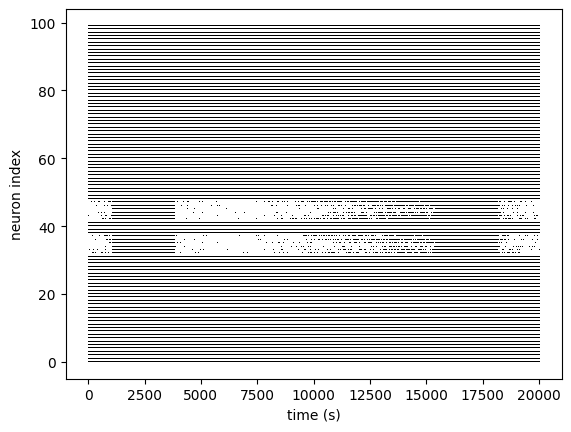

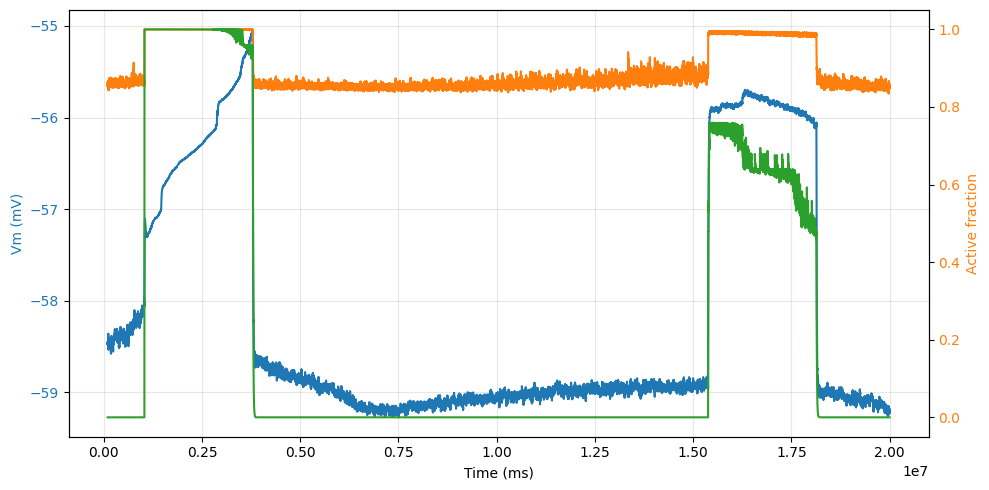

In [43]:
start_scope()
defaultclock.dt = 1000 * us
net = test(1,show_time=20000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
z_t=net['z_t']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.1 
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

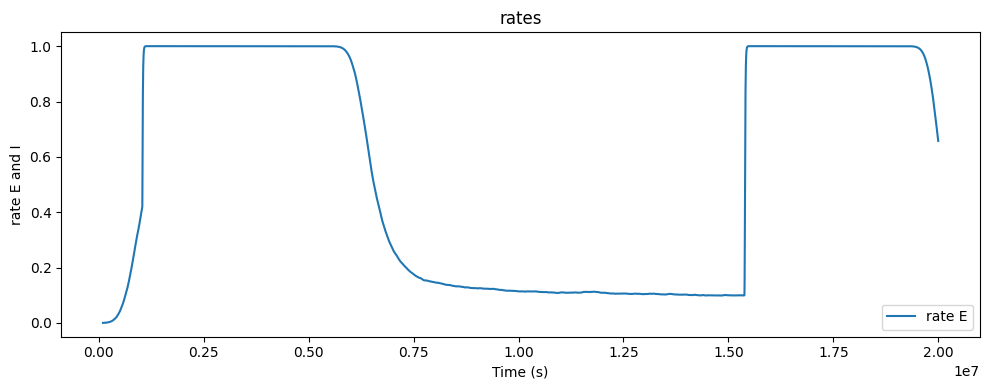

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(z_t.t[500:]/ms, z_t.z[0,500:], color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('z(t)')
plt.title('rates')
plt.legend()
plt.tight_layout()

INFO:root:building '_cython_magic_af06deb02f7a348963115e83930d903a' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_af06deb02f7a348963115e83930d903a.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_af06deb02f7a348963115e83930d903a.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_af06deb02f7a348963115e83930d903a.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([39.44428814, 40.35436453, 43.59937359, ..., 35.54986351,
       38.82592698, 40.38338656]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 20. ks
137.695 s (0%) simulated in 10s, estimated 24m 2s remaining.
274.178 s (1%) simulated in 20s, estimated 23m 59s remaining.
0.402057 ks (2%) simulated in 30s, estimated 24m 22s remaining.
0.516289 ks (2%) simulated in 40s, estimated 25m 10s remaining.
0.635798 ks (3%) simulated in 50s, estimated 25m 23s remaining.
0.749006 ks (3%) simulated in 1m 0s, estimated 25m 42s remaining.
0.861129 ks (4%) simulated in 1m 10s, estimated 25m 56s remaining.
0.981115 ks (4%) simulated in 1m 20s, estimated 25m 51s remaining.
1.094937 ks (5%) simulated in 1m 30s, estimated 25m 54s remaining.
1.196608 ks (5%) simulated in 1m 40s, estimated 26m 11s remaining.
1.284954 ks (6%) simulated in 1m 50s, estimated 26m 42s remaining.
1.394075 ks (6%) simulated in 2m 0s, estimated 26m 42s remaining.
1.504216 ks (7%) simulated in 2m 10s, estimated 26m 38s remaining.
1.60758 ks (8%) simulated in 2m 20s, estimated 26m 42s remaining.
1.711218 ks (8%) simulated in 

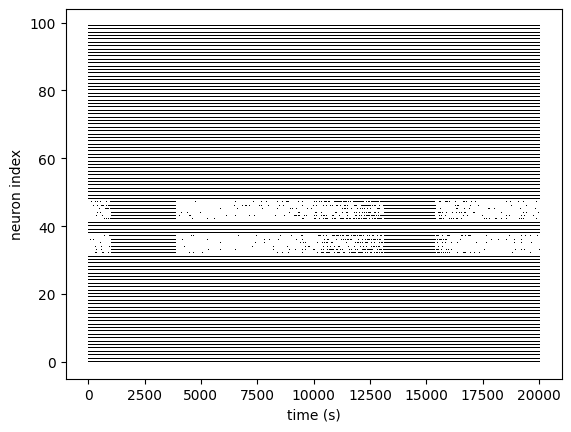

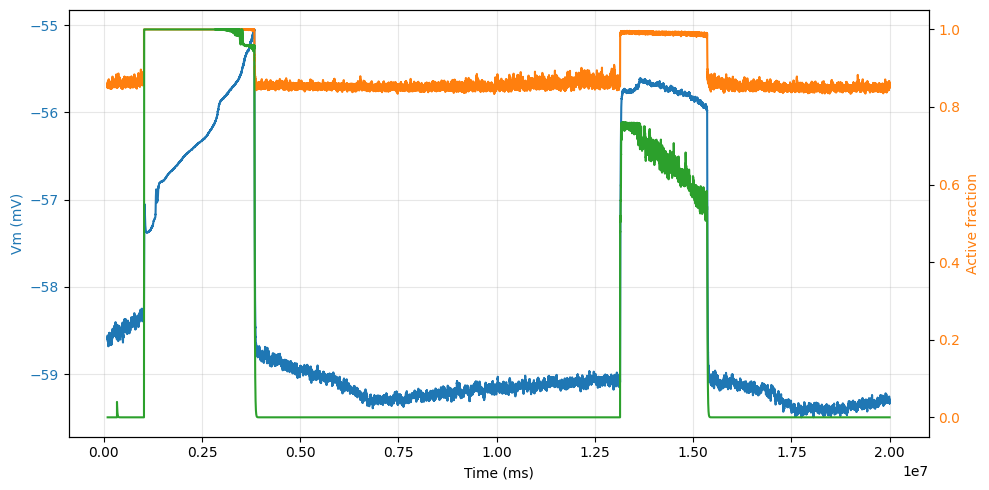

In [20]:
start_scope()
defaultclock.dt = 1000 * us
net = test(1,show_time=20000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.1 
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

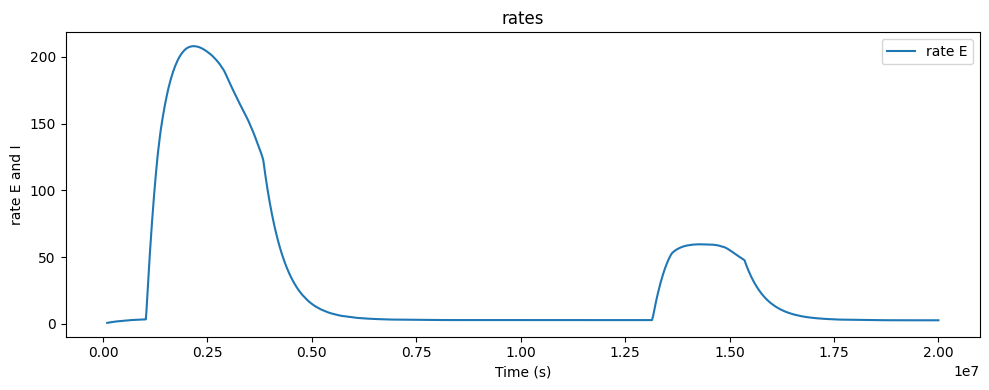

In [21]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E and I')
plt.title('rates')
plt.legend()
plt.tight_layout()

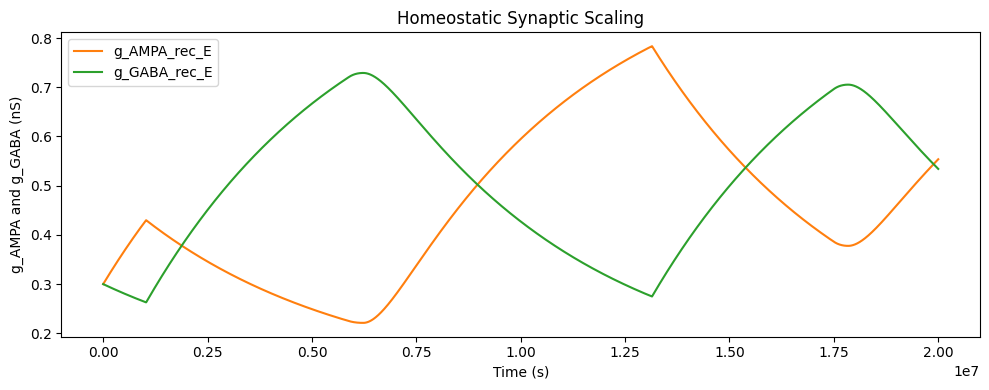

In [22]:
gAMPA_mon_E=net['g_AMPA_E_hsp']
gGABA_mon_E=net['g_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(gAMPA_mon_E.t/ms, gAMPA_mon_E.g_AMPA_E_hsp[45], label='g_AMPA_rec_E',color='tab:orange')
plt.plot(gGABA_mon_E.t/ms, gGABA_mon_E.g_GABA_E_hsp[45], label='g_GABA_rec_E',color='tab:green')
plt.xlabel('Time (s)')
plt.ylabel('g_AMPA and g_GABA (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()

<Axes: xlabel='time (s)', ylabel='neuron index'>

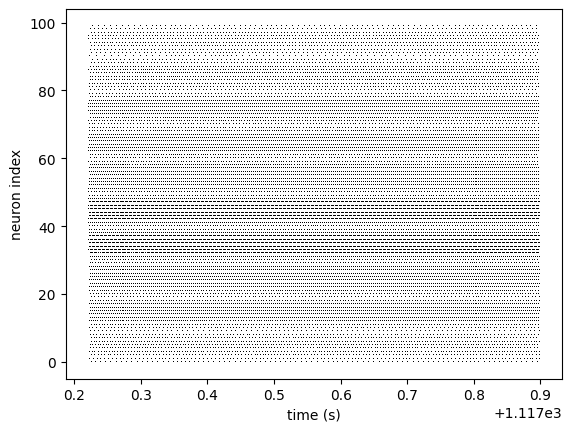

In [26]:
plot_raster(spE.i[int(3.0*10**6):int(3.02*10**6)], spE.t[int(3.*10**6):int(3.02*10**6)], time_unit=second, marker=',', color='k')

<Axes: xlabel='time (s)', ylabel='neuron index'>

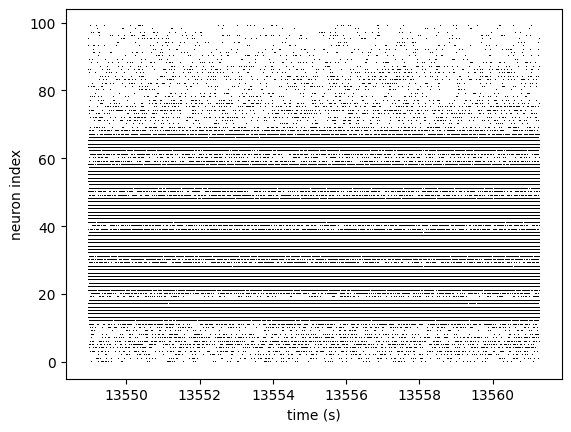

In [38]:
plot_raster(spE.i[int(6.0*10**7):int(6.01*10**7)], spE.t[int(6.*10**7):int(6.01*10**7)], time_unit=second, marker=',', color='k')

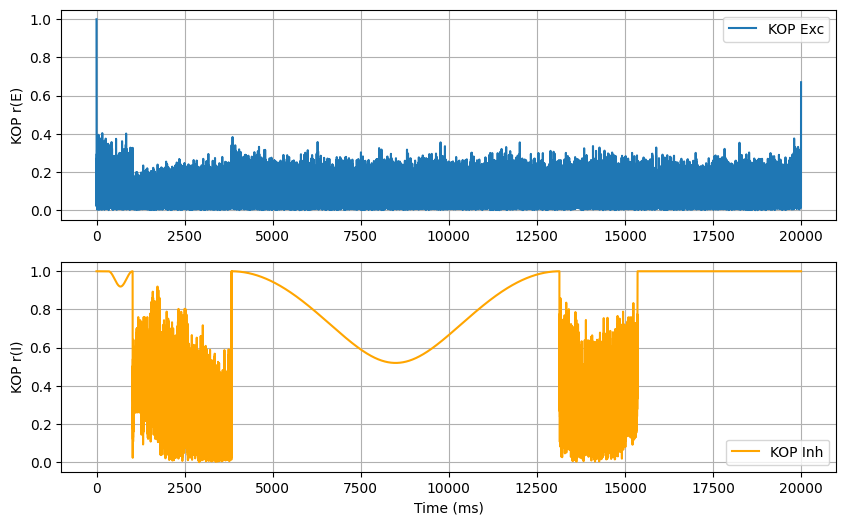

In [23]:
plt.figure(figsize=(10,6))

plt.subplot(2,1,1)
plt.plot(t_grid, rE, label='KOP Exc')
plt.ylabel(f'KOP r(E)')
plt.legend()
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(t_grid, rI, color='orange', label='KOP Inh')
plt.xlabel('Time (ms)')
plt.ylabel(f'KOP r(I)')
plt.legend()
plt.grid(True)

In [45]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 15. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 500*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second

tau_z   = 10*second      
r0      = 3*Hz           # baseline E population rate
kz      = 8.0            # sigmoid steepness
u0      = 0.2            

Iz_max_E = 50*pA         
eta_I    = 0 #0.3  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


kill_mask = np.ones(100, dtype=np.float32)
#kill_mask[range(40,47)]=0 #yes
#kill_mask[np.array([range(40,47),range(21,28)]).flatten()]=0 #yes
kill_mask[np.array([range(42,48),range(32,38)]).flatten()]=0



def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * g_AMPA_E_hsp * (1 + 0.1*z_shared) * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E    * g_GABA_E_hsp  * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     :1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1
    z_shared : 1 (linked)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dg_AMPA_E_hsp/dt = ((1 - g_AMPA_E_hsp) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_ins_AMPA_E
                - (g_AMPA_E_hsp - 0.1) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_int_AMPA_E) : 1

    dg_GABA_E_hsp/dt = (-(g_GABA_E_hsp - 0.1) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_int_GABA_E
                + (1 - g_GABA_E_hsp) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (1 + 0.1*z_shared) * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp  * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    z_shared : 1 (linked)

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((-r_est +target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((-r_est + target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''
    z_container = NeuronGroup(1, '''
            r_in : Hz  
            u = r_in/r0 - 1 : 1
            s = 1/(1 + exp(-kz*(u - u0))) : 1
            dz/dt = (s - z)/tau_z : 1
        ''', method='euler', name='z_container')

    z_container.z = 0.0
    z_container.r_in = r0

    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.g_AMPA_E_hsp = 0.3  
    P_E.g_GABA_E_hsp = 0.3  
    P_E.tau_ins_AMPA_E = 5000*second   #50'000
    P_E.tau_int_AMPA_E = 5000*second    #5'000
    P_E.tau_ins_GABA_E = 5000*second   
    P_E.tau_int_GABA_E = 5000*second   
    P_E.z_shared = linked_var(z_container, 'z')


    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.3  
    P_I.g_GABA_I_hsp = 0.3  
    P_I.tau_ins_AMPA_I = 500000000*second   
    P_I.tau_int_AMPA_I = 50000000*second    
    P_I.tau_ins_GABA_I = 500000000*second   
    P_I.tau_int_GABA_I = 50000000*second
    P_I.z_shared = linked_var(z_container, 'z')

    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(j='i')                 

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
            s_AMPA_ext += w  
            ''', method='euler', name='PG_E')
        C_PG_E.connect(j='i')  

        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
            s_AMPA += w  
            ''', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        ''', method='euler', name='E_I') #        x_postE_post += 1.0 
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.2
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        # w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        # w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        # w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        # w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        # w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    C_r_to_z = Synapses(rate_container_E, z_container,
                    model='r_in_post = r_pop_E_pre : Hz (summed)',
                    method='euler', name='C_r_to_z')
    C_r_to_z.connect(i=0, j=0)

    # C_zE = Synapses(z_container, P_E,
    #             model='z_shared_post = z_pre : 1 (summed)',
    #             method='euler')
    # C_zE.connect()

    # C_zI = Synapses(z_container, P_I,
    #                 model='z_shared_post = z_pre : 1 (summed)',
    #                 method='euler')
    # C_zI.connect()
    
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    z_mon = StateMonitor(z_container, 'z', record=True, dt=record_dt,name='z_t')

    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'g_AMPA_E_hsp', record=True, dt=record_dt, name='g_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'g_GABA_E_hsp', record=True, dt=record_dt, name='g_GABA_E_hsp')
    gAMPA_mon_I = StateMonitor(P_I, 'g_AMPA_I_hsp', record=True, dt=record_dt, name='g_AMPA_I_hsp')
    gGABA_mon_I = StateMonitor(P_I, 'g_GABA_I_hsp', record=True, dt=record_dt, name='g_GABA_I_hsp')

    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')

# def train(N_train,alcohol,target_rate = 10*Hz):
#     net = build_network(True,alcohol=alcohol,target_rate=target_rate)
#     for i in range(N_train): 
#         show_img(net, index = i)
#         print(i)

#     save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
#     save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
#     save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
#     save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
#     save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
#     return net


def test(N_test,show_time = 1000*ms):
    net = build_network(False)
    for i in range(N_test):
        show_rand_rate(net,show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


INFO:root:building '_cython_magic_3382e361d47f4e4604411abd8691cd6a' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_3382e361d47f4e4604411abd8691cd6a.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_3382e361d47f4e4604411abd8691cd6a.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_3382e361d47f4e4604411abd8691cd6a.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([41.08930267, 44.83274692, 42.27253536, ..., 40.92761064,
       39.57807728, 40.73014052]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 10. ks
140.344 s (1%) simulated in 10s, estimated 11m 43s remaining.
282.032 s (2%) simulated in 20s, estimated 11m 29s remaining.
0.411647 ks (4%) simulated in 30s, estimated 11m 39s remaining.
0.549871 ks (5%) simulated in 40s, estimated 11m 27s remaining.
0.689131 ks (6%) simulated in 50s, estimated 11m 16s remaining.
0.827289 ks (8%) simulated in 1m 0s, estimated 11m 5s remaining.
0.969746 ks (9%) simulated in 1m 10s, estimated 10m 52s remaining.
1.099393 ks (10%) simulated in 1m 20s, estimated 10m 48s remaining.
1.229712 ks (12%) simulated in 1m 30s, estimated 10m 42s remaining.
1.37087 ks (13%) simulated in 1m 40s, estimated 10m 29s remaining.
1.506637 ks (15%) simulated in 1m 50s, estimated 10m 20s remaining.
1.65098 ks (16%) simulated in 2m 0s, estimated 10m 7s remaining.
1.794147 ks (17%) simulated in 2m 10s, estimated 9m 55s remaining.
1.936591 ks (19%) simulated in 2m 20s, estimated 9m 43s remaining.
2.081716 ks (20%) simulated

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



Tested image 1/1


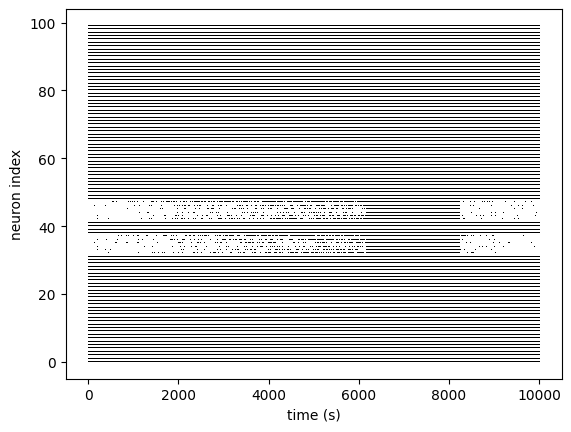

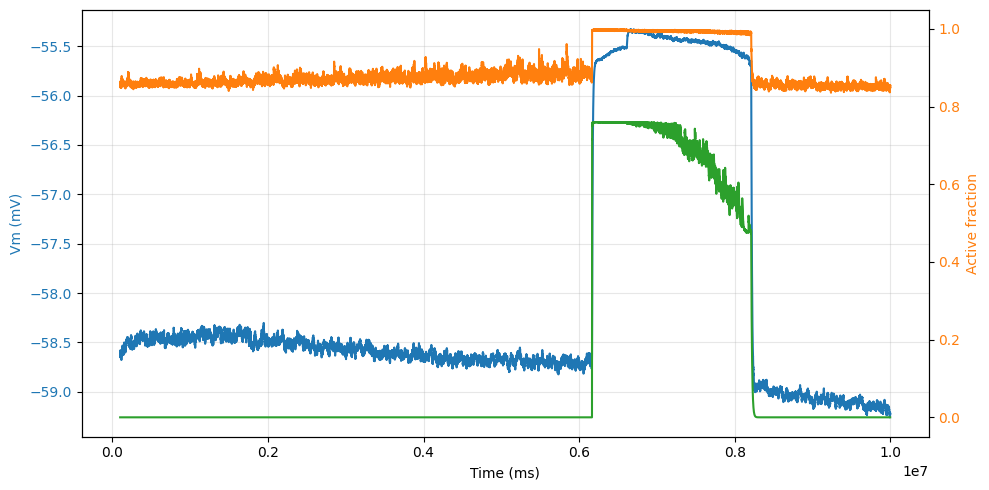

In [46]:
start_scope()
defaultclock.dt = 1000 * us
net = test(1,show_time=10000*second)


V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.1 
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

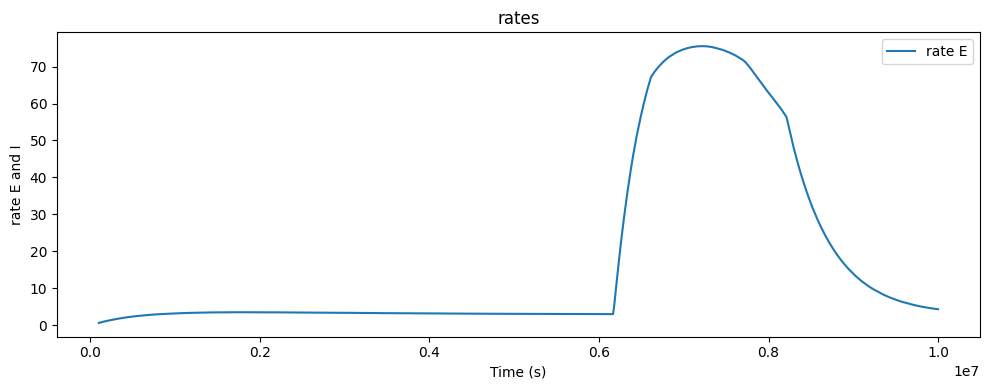

In [47]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
#plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E and I')
plt.title('rates')
plt.legend()
plt.tight_layout()

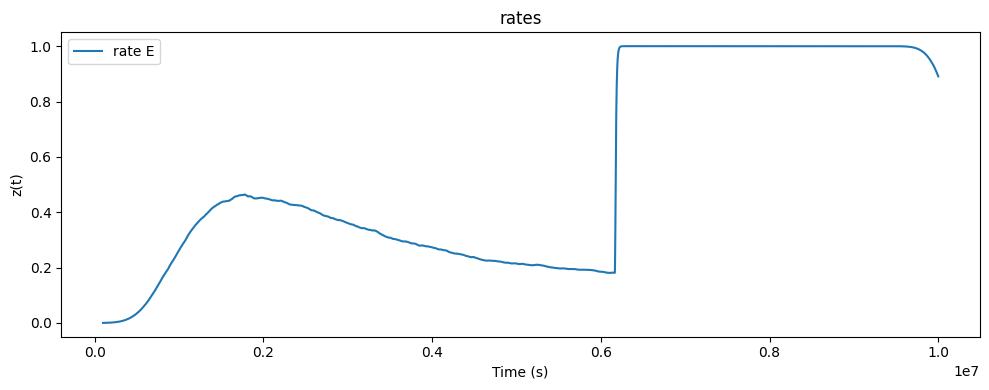

In [49]:
z_t=net['z_t']
plt.figure(figsize=(10, 4))
plt.plot(z_t.t[500:]/ms, z_t.z[0,500:], color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('z(t)')
plt.title('rates')
plt.legend()
plt.tight_layout()